# Audio Loading and Playback

In [7]:
from pathlib import Path

import numpy as np
import pandas as pd
import librosa
import librosa.display
import matplotlib.pyplot as plt
import soundfile as sf
from IPython.display import Audio, display

# Project directory
PROJECT_DIR = Path.cwd().parent

# Load metadata
metadata_path = PROJECT_DIR / "data" / "processed" / "metadata.csv"

df = pd.read_csv(metadata_path)

print("Metadata loaded:", df.shape)

Metadata loaded: (1440, 16)


In [8]:
emotion_samples = (
    df.groupby("emotion_label", sort=True)
    .first()
    .reset_index()
)

emotion_samples[["emotion_label", "recording_id", "file_path"]]

,emotion_label,recording_id,file_path
0,Angry,03-01-05-01-01-01-01,Y:\Python\AI ML\Month 2\week 8-NLP\49 — SPEECH...
1,Calm,03-01-02-01-01-01-01,Y:\Python\AI ML\Month 2\week 8-NLP\49 — SPEECH...
2,Disgust,03-01-07-01-01-01-01,Y:\Python\AI ML\Month 2\week 8-NLP\49 — SPEECH...
3,Fearful,03-01-06-01-01-01-01,Y:\Python\AI ML\Month 2\week 8-NLP\49 — SPEECH...
4,Happy,03-01-03-01-01-01-01,Y:\Python\AI ML\Month 2\week 8-NLP\49 — SPEECH...
5,Neutral,03-01-01-01-01-01-01,Y:\Python\AI ML\Month 2\week 8-NLP\49 — SPEECH...
6,Sad,03-01-04-01-01-01-01,Y:\Python\AI ML\Month 2\week 8-NLP\49 — SPEECH...
7,Surprised,03-01-08-01-01-01-01,Y:\Python\AI ML\Month 2\week 8-NLP\49 — SPEECH...


In [9]:
for i in range(0,8):

    sample_path = emotion_samples.iloc[i]["file_path"]
    
    audio, sr = librosa.load(sample_path, sr=None)
    
    print("Emotion:", emotion_samples.iloc[i]["emotion_label"])
    print("Sample rate:", sr)
    print("Duration:", len(audio) / sr)
    
    display(Audio(audio, rate=sr))
    print()

Emotion: Angry
Sample rate: 48000
Duration: 3.8705416666666665



Emotion: Calm
Sample rate: 48000
Duration: 3.5368541666666666



Emotion: Disgust
Sample rate: 48000
Duration: 3.8705208333333334



Emotion: Fearful
Sample rate: 48000
Duration: 3.6703333333333332



Emotion: Happy
Sample rate: 48000
Duration: 3.4701458333333335



Emotion: Neutral
Sample rate: 48000
Duration: 3.3032916666666665



Emotion: Sad
Sample rate: 48000
Duration: 3.8371666666666666



Emotion: Surprised
Sample rate: 48000
Duration: 3.403395833333333


# Compare all eight emotion waveforms

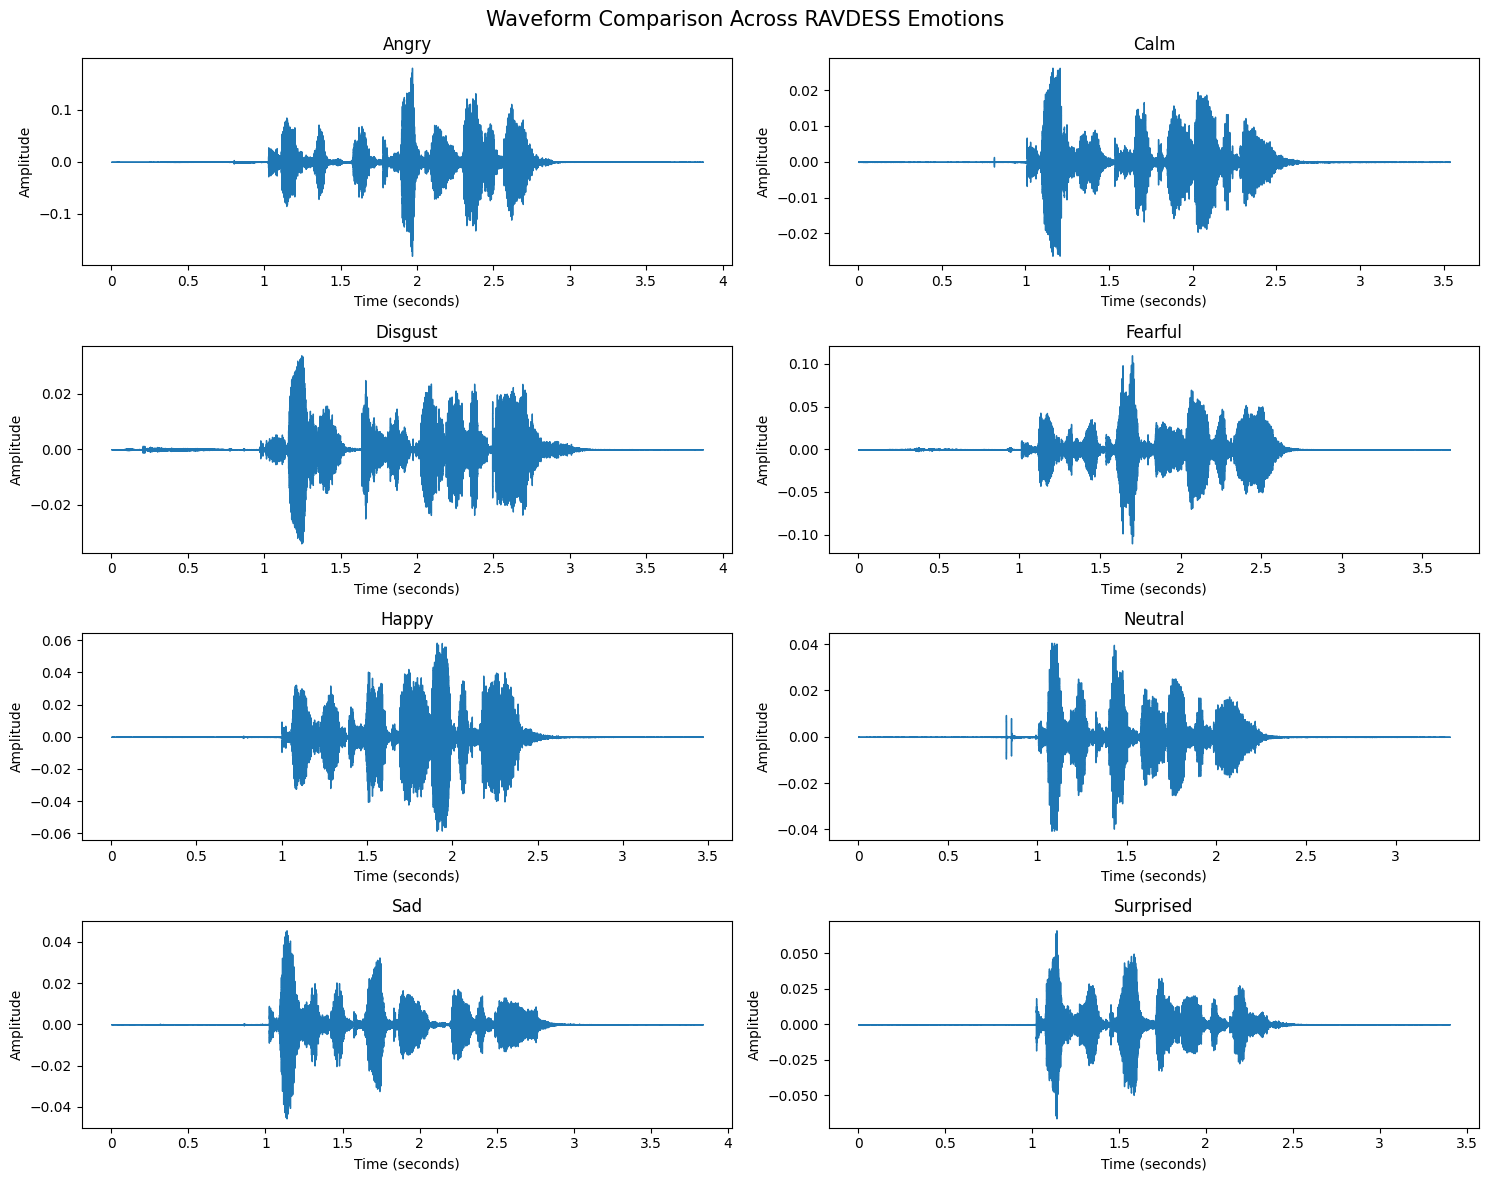

In [10]:
fig, axes = plt.subplots(
    nrows=4,
    ncols=2,
    figsize=(15, 12)
)

axes = axes.flatten()

for index, row in emotion_samples.iterrows():

    audio, sr = librosa.load(
        row["file_path"],
        sr=None
    )

    librosa.display.waveshow(
        audio,
        sr=sr,
        ax=axes[index]
    )

    axes[index].set_title(row["emotion_label"])
    axes[index].set_xlabel("Time (seconds)")
    axes[index].set_ylabel("Amplitude")

plt.suptitle(
    "Waveform Comparison Across RAVDESS Emotions",
    fontsize=15
)

plt.tight_layout()
plt.show()

In [11]:
waveform_stats = []

for _, row in emotion_samples.iterrows():

    audio, sr = librosa.load(
        row["file_path"],
        sr=None
    )

    waveform_stats.append({
        "emotion": row["emotion_label"],
        "duration": len(audio) / sr,
        "max_amplitude": np.max(np.abs(audio)),
        "mean_amplitude": np.mean(np.abs(audio)),
        "peak_to_peak": np.ptp(audio)
    })

waveform_stats_df = pd.DataFrame(waveform_stats)

waveform_stats_df

,emotion,duration,max_amplitude,mean_amplitude,peak_to_peak
0,Angry,3.870542,0.180969,0.006290,0.330719
1,Calm,3.536854,0.026245,0.001265,0.052460
2,Disgust,3.870521,0.033966,0.001979,0.067627
3,Fearful,3.670333,0.110260,0.004573,0.196381
4,Happy,3.470146,0.058502,0.003189,0.107391
5,Neutral,3.303292,0.040588,0.001663,0.079010
6,Sad,3.837167,0.045624,0.001597,0.082336
7,Surprised,3.403396,0.066223,0.002295,0.129669


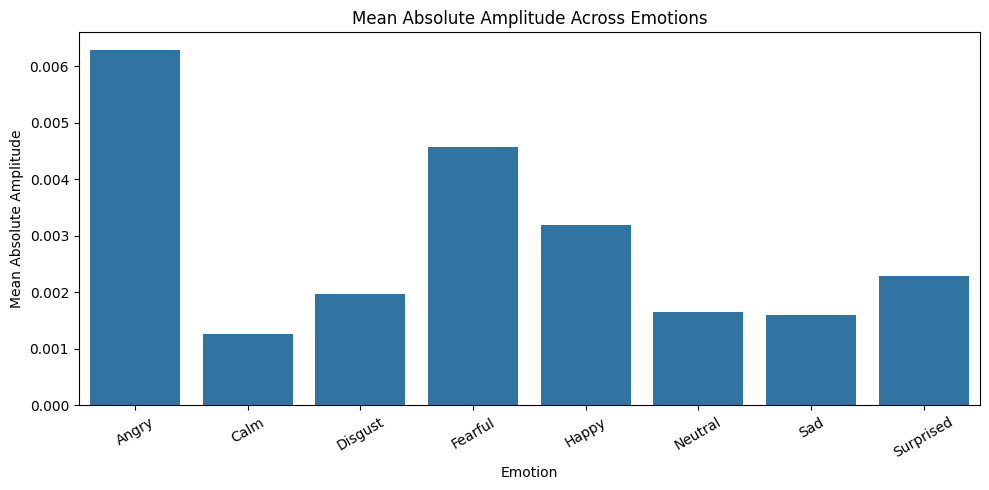

In [13]:
# visualizing the amplitude differences
import seaborn as sns 

plt.figure(figsize=(10, 5))

sns.barplot(
    data=waveform_stats_df,
    x="emotion",
    y="mean_amplitude"
)

plt.title("Mean Absolute Amplitude Across Emotions")
plt.xlabel("Emotion")
plt.ylabel("Mean Absolute Amplitude")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

# STFT and Spectrogram Analysis

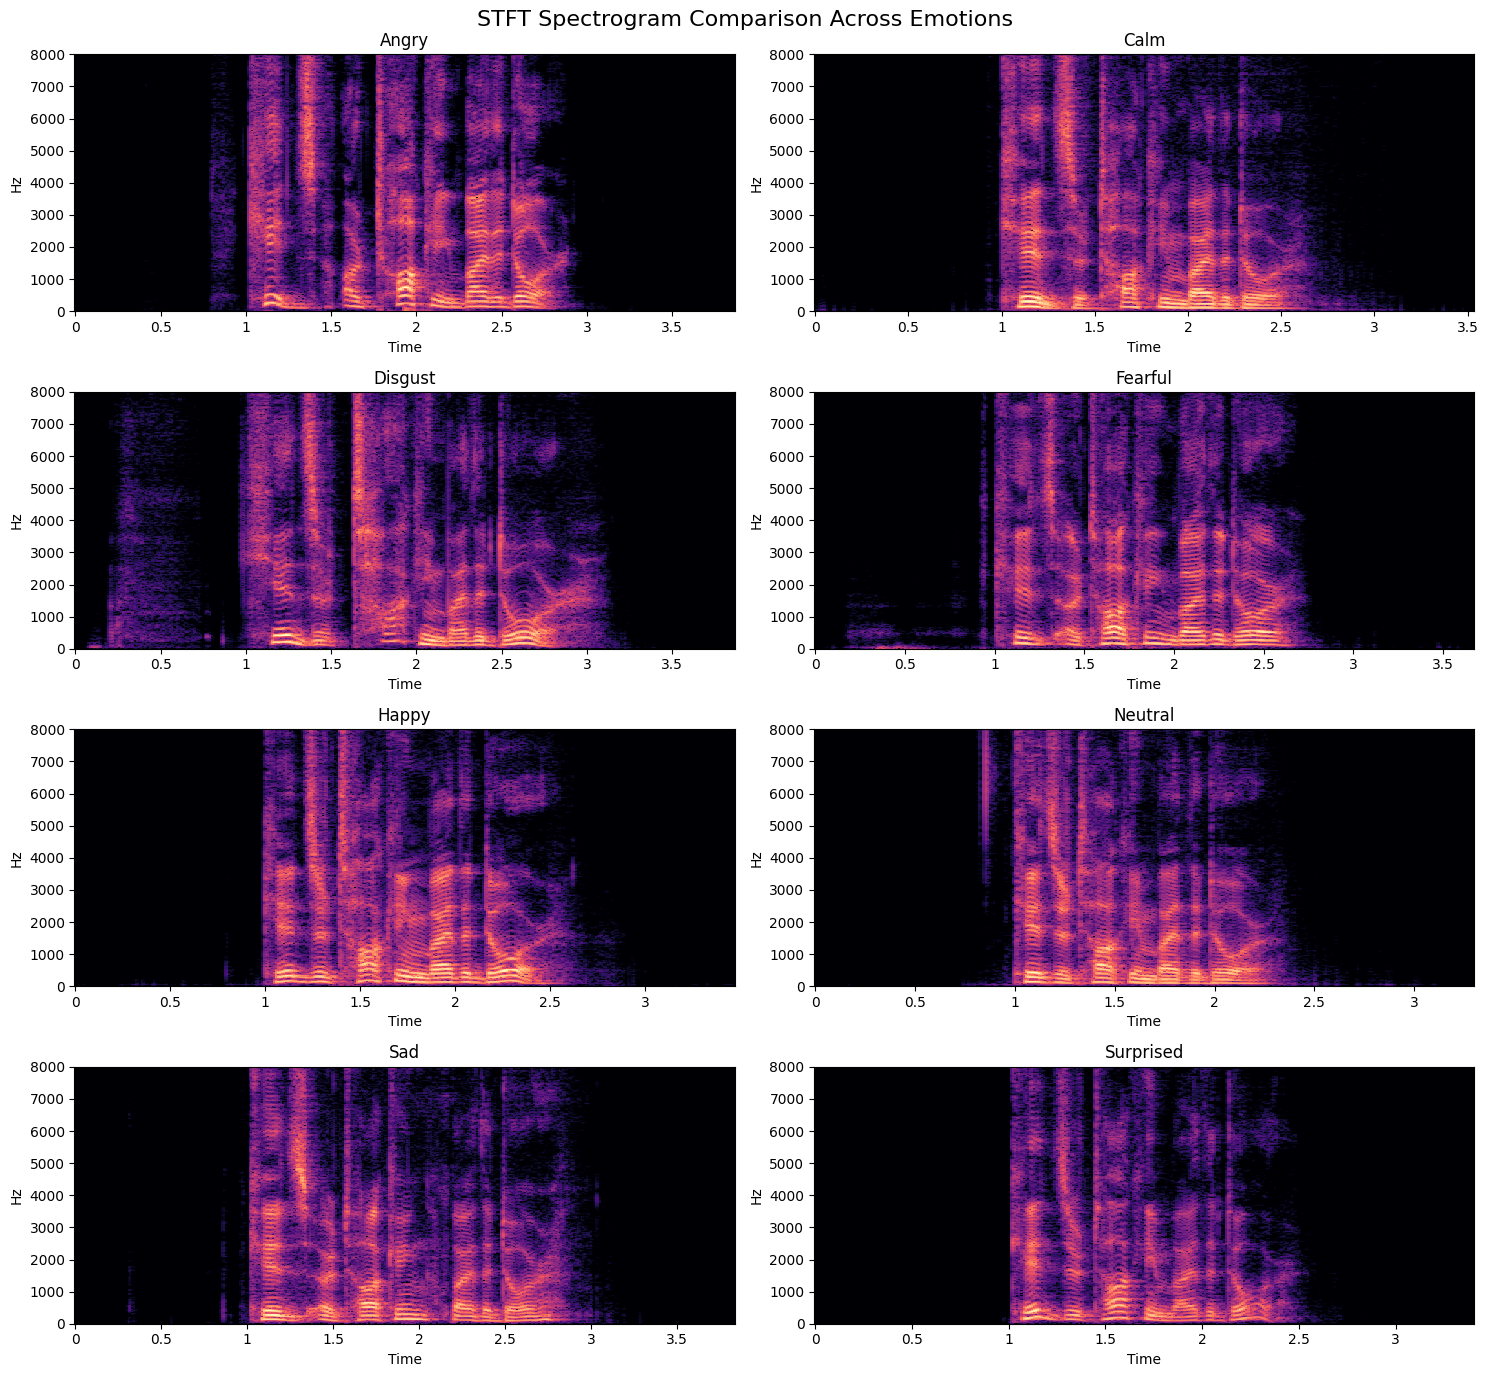

In [14]:
fig, axes = plt.subplots(
    nrows=4,
    ncols=2,
    figsize=(15, 14)
)

axes = axes.flatten()

for index, row in emotion_samples.iterrows():

    audio, sr = librosa.load(
        row["file_path"],
        sr=None
    )

    D = librosa.stft(
        audio,
        n_fft=2048,
        hop_length=512
    )

    S_db = librosa.amplitude_to_db(
        np.abs(D),
        ref=np.max
    )

    librosa.display.specshow(
        S_db,
        sr=sr,
        hop_length=512,
        x_axis="time",
        y_axis="hz",
        ax=axes[index]
    )

    axes[index].set_title(row["emotion_label"])
    axes[index].set_ylim(0, 8000)

plt.suptitle(
    "STFT Spectrogram Comparison Across Emotions",
    fontsize=16
)

plt.tight_layout()
plt.show()

# Compare frequency energy distribution

In [15]:
frequency_stats = []

for _, row in emotion_samples.iterrows():

    audio, sr = librosa.load(
        row["file_path"],
        sr=None
    )

    D = np.abs(
        librosa.stft(audio, n_fft=2048, hop_length=512)
    )

    frequencies = librosa.fft_frequencies(
        sr=sr,
        n_fft=2048
    )

    power = D ** 2

    frequency_stats.append({
        "emotion": row["emotion_label"],
        "low_frequency": power[frequencies < 500].mean(),
        "mid_frequency": power[
            (frequencies >= 500) & (frequencies < 4000)
        ].mean(),
        "high_frequency": power[frequencies >= 4000].mean()
    })

frequency_stats_df = pd.DataFrame(frequency_stats)

frequency_stats_df

,emotion,low_frequency,mid_frequency,high_frequency
0,Angry,3.662472,0.619123,0.006589
1,Calm,0.242840,0.009536,0.000119
2,Disgust,0.592024,0.012622,0.000522
3,Fearful,1.828412,0.264149,0.000722
4,Happy,1.164009,0.097134,0.000348
5,Neutral,0.368804,0.029191,0.000130
6,Sad,0.371446,0.016444,0.000425
7,Surprised,0.828843,0.054332,0.000231


# Log-Mel Spectrogram Analysis

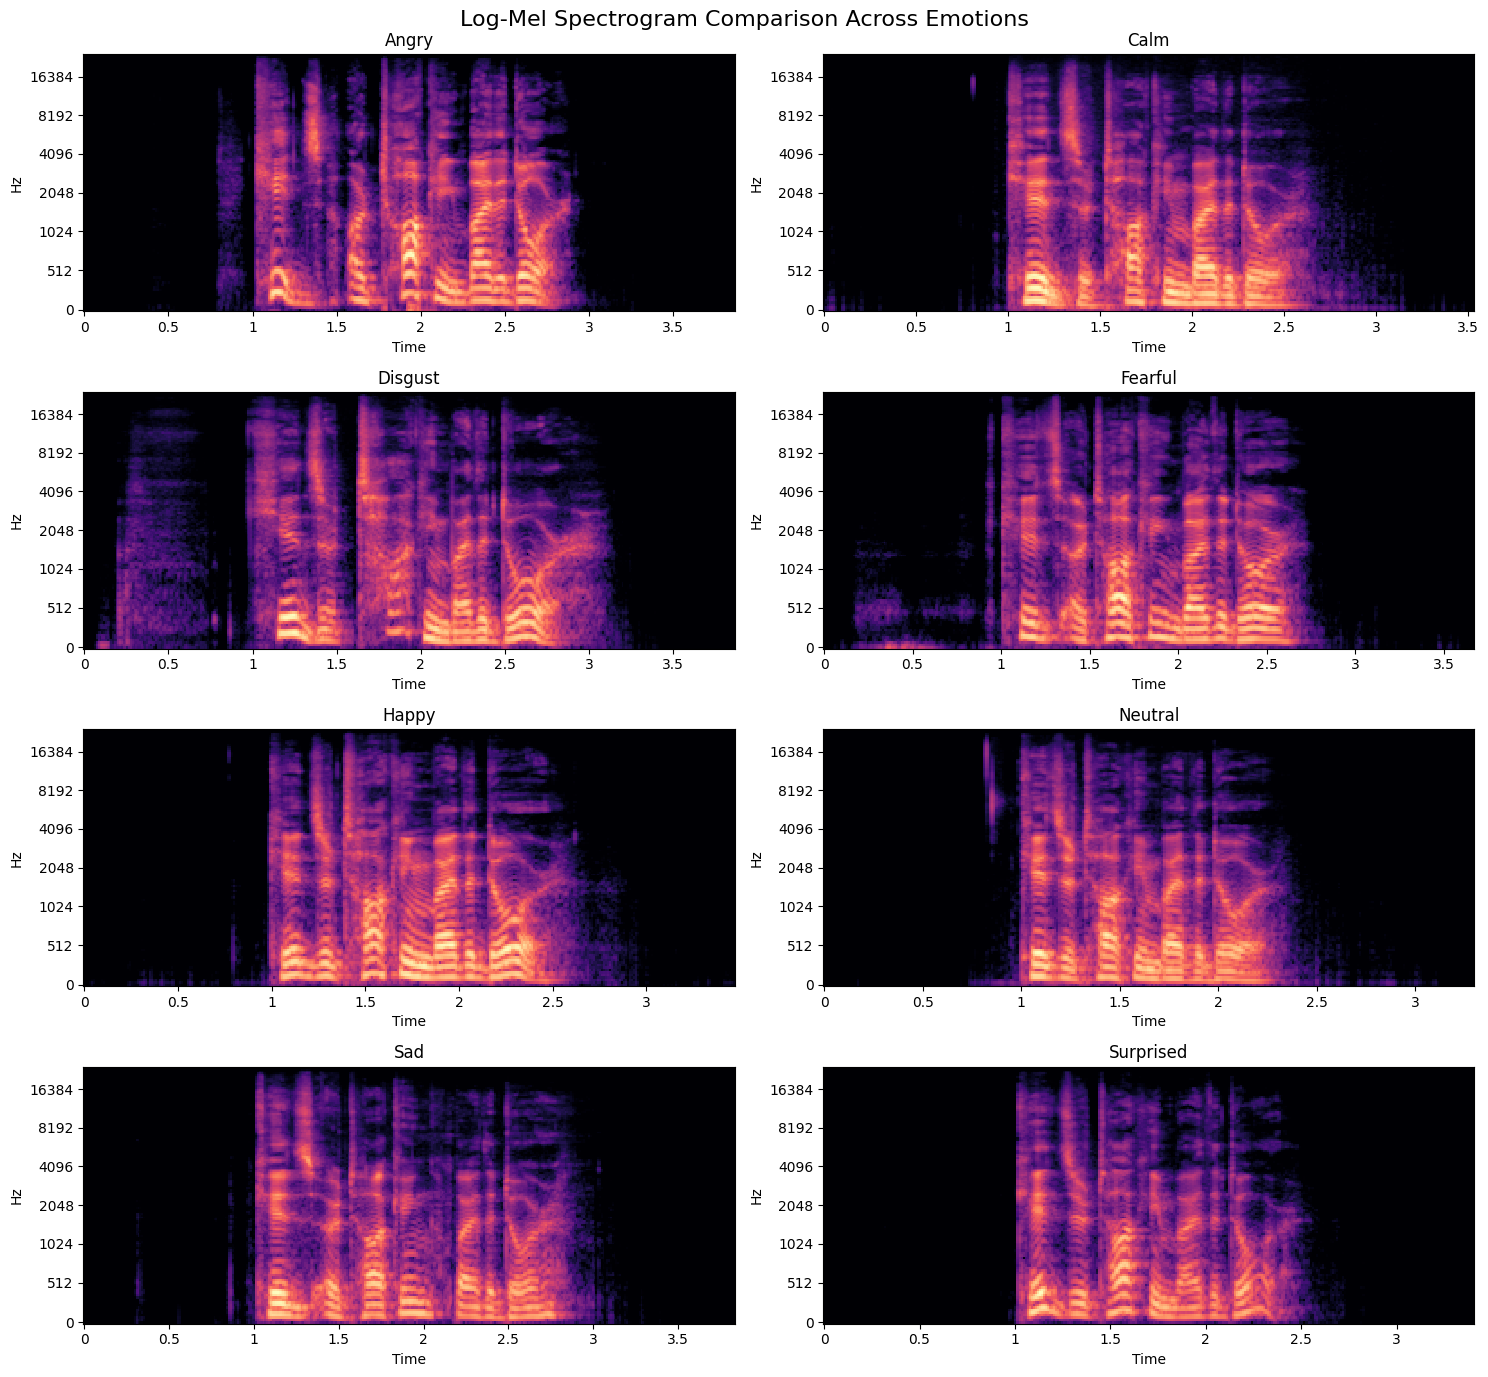

In [16]:
fig, axes = plt.subplots(
    nrows=4,
    ncols=2,
    figsize=(15, 14)
)

axes = axes.flatten()

for index, row in emotion_samples.iterrows():

    audio, sr = librosa.load(
        row["file_path"],
        sr=None
    )

    mel_spec = librosa.feature.melspectrogram(
        y=audio,
        sr=sr,
        n_fft=2048,
        hop_length=512,
        n_mels=128,
        fmin=0,
        fmax=sr // 2
    )

    log_mel = librosa.power_to_db(
        mel_spec,
        ref=np.max
    )

    librosa.display.specshow(
        log_mel,
        sr=sr,
        hop_length=512,
        x_axis="time",
        y_axis="mel",
        ax=axes[index]
    )

    axes[index].set_title(row["emotion_label"])

plt.suptitle(
    "Log-Mel Spectrogram Comparison Across Emotions",
    fontsize=16
)

plt.tight_layout()
plt.show()

# Compare Log-Mel feature dimensions


In [17]:
log_mel_shapes = []

for _, row in emotion_samples.iterrows():

    audio, sr = librosa.load(
        row["file_path"],
        sr=None
    )

    mel_spec = librosa.feature.melspectrogram(
        y=audio,
        sr=sr,
        n_fft=2048,
        hop_length=512,
        n_mels=128
    )

    log_mel = librosa.power_to_db(
        mel_spec,
        ref=np.max
    )

    log_mel_shapes.append({
        "emotion": row["emotion_label"],
        "frequency_bins": log_mel.shape[0],
        "time_frames": log_mel.shape[1]
    })

log_mel_shapes_df = pd.DataFrame(log_mel_shapes)

log_mel_shapes_df

,emotion,frequency_bins,time_frames
0,Angry,128,363
1,Calm,128,332
2,Disgust,128,363
3,Fearful,128,345
4,Happy,128,326
5,Neutral,128,310
6,Sad,128,360
7,Surprised,128,320


# MFCC Analysis

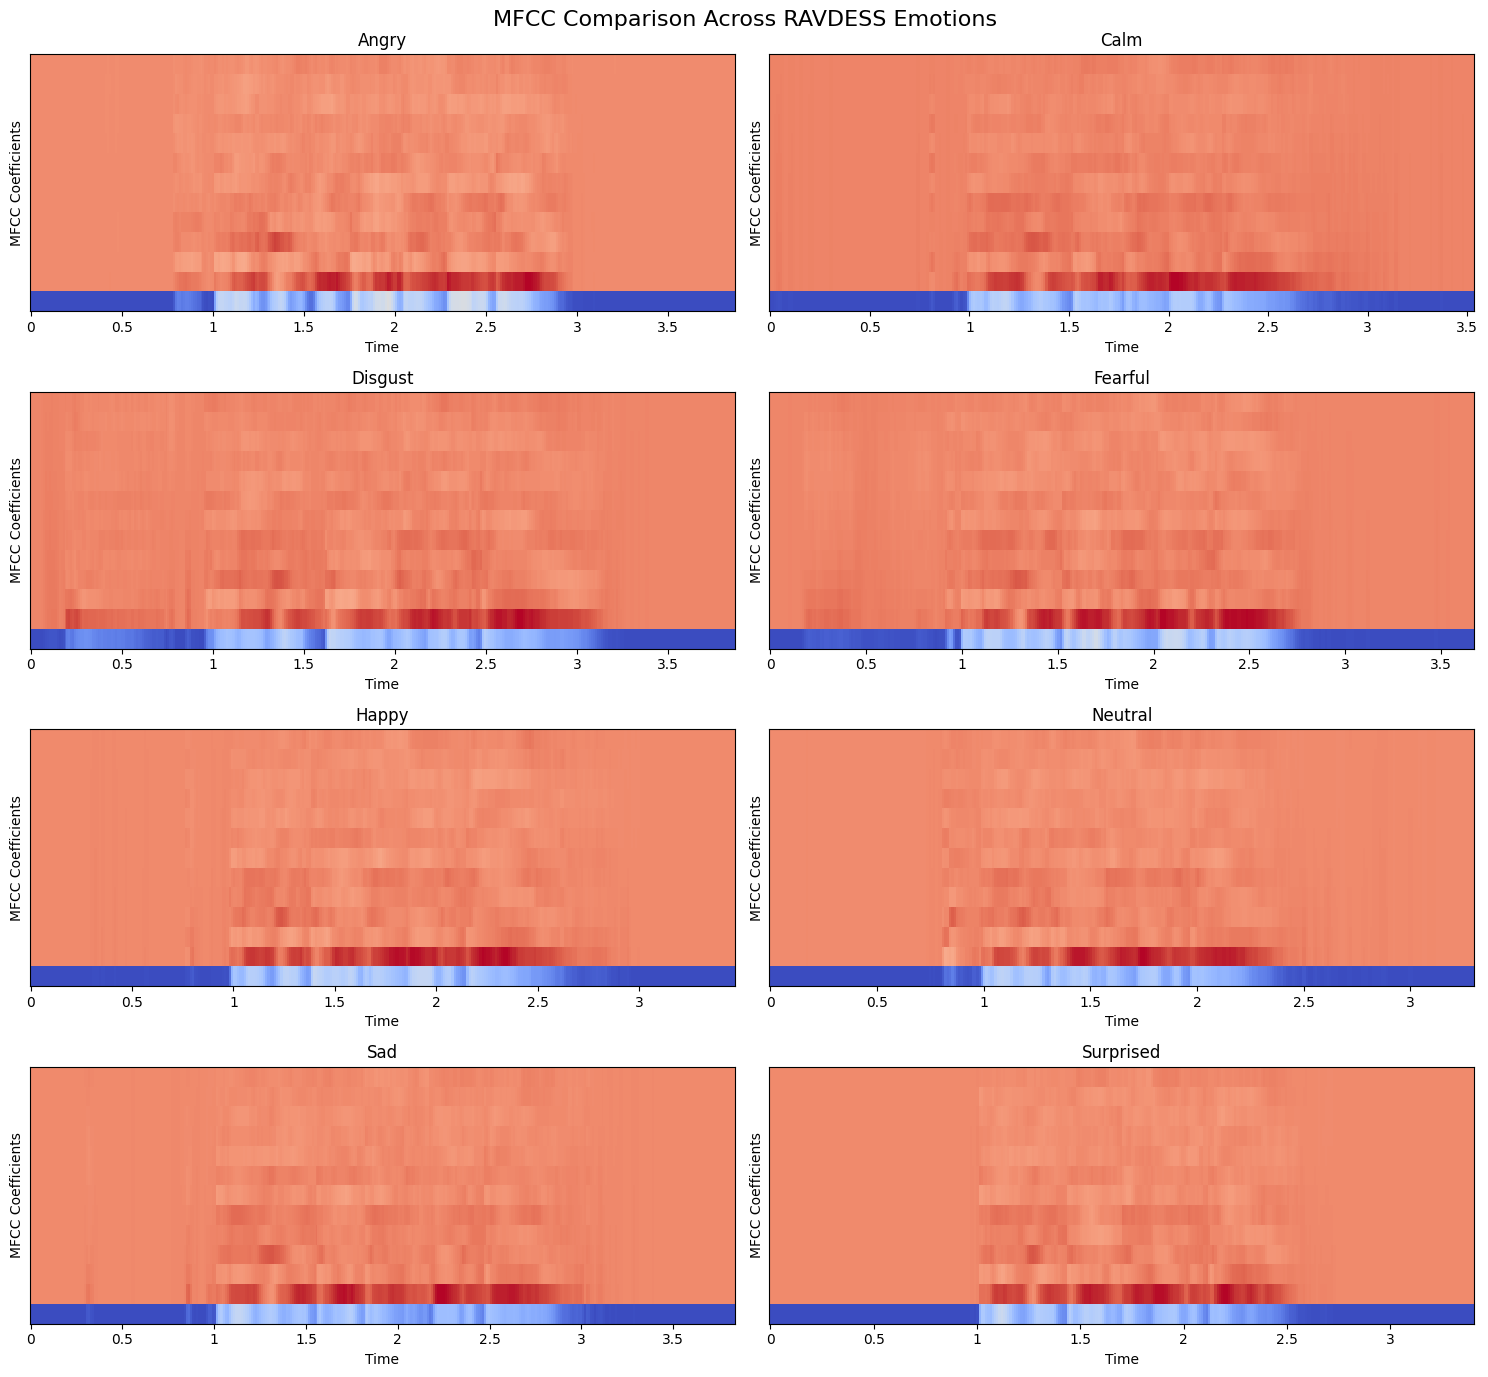

In [18]:
fig, axes = plt.subplots(
    nrows=4,
    ncols=2,
    figsize=(15, 14)
)

axes = axes.flatten()

for index, row in emotion_samples.iterrows():

    audio, sr = librosa.load(
        row["file_path"],
        sr=None
    )

    mfcc = librosa.feature.mfcc(
        y=audio,
        sr=sr,
        n_mfcc=13,
        n_fft=2048,
        hop_length=512,
        n_mels=128
    )

    librosa.display.specshow(
        mfcc,
        sr=sr,
        hop_length=512,
        x_axis="time",
        ax=axes[index]
    )

    axes[index].set_title(row["emotion_label"])
    axes[index].set_ylabel("MFCC Coefficients")

plt.suptitle(
    "MFCC Comparison Across RAVDESS Emotions",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [19]:
# compare MFCC coefficients 

mfcc_statistics = []

for _, row in emotion_samples.iterrows():

    audio, sr = librosa.load(
        row["file_path"],
        sr=None
    )

    mfcc = librosa.feature.mfcc(
        y=audio,
        sr=sr,
        n_mfcc=13,
        n_fft=2048,
        hop_length=512,
        n_mels=128
    )

    mean_mfcc = np.mean(mfcc, axis=1)

    feature_row = {
        "emotion": row["emotion_label"]
    }

    for i, value in enumerate(mean_mfcc):
        feature_row[f"MFCC_{i+1}"] = value

    mfcc_statistics.append(feature_row)

mfcc_statistics_df = pd.DataFrame(mfcc_statistics)

mfcc_statistics_df

,emotion,MFCC_1,MFCC_2,MFCC_3,MFCC_4,MFCC_5,MFCC_6,MFCC_7,MFCC_8,MFCC_9,MFCC_10,MFCC_11,MFCC_12,MFCC_13
0,Angry,-578.988647,62.405315,-8.723745,13.807444,1.789455,6.853797,-6.779374,1.681231,-3.129483,-0.872465,-9.711343,-3.922254,1.189844
1,Calm,-759.921753,75.783524,6.023605,14.557394,6.454188,14.631508,-3.004551,4.620970,-5.200016,-0.707430,-7.790287,-3.564949,2.180970
2,Disgust,-681.221497,78.883621,0.128675,11.795810,0.987660,13.565272,-6.526605,3.732994,-9.424510,-3.314810,-10.499207,-4.464768,2.716594
3,Fearful,-620.869263,72.925552,3.069638,15.845616,5.005441,15.862975,-6.974336,2.558235,-6.399506,-6.247275,-8.195704,-2.013455,0.490494
4,Happy,-679.538757,78.698463,0.667737,10.390019,5.207020,11.525229,-7.043530,2.034919,-6.769451,-3.452317,-8.604058,-2.143097,2.153603
5,Neutral,-726.217224,68.541420,3.293398,12.205300,5.510278,13.667408,-2.983828,3.098029,-3.310813,-1.564384,-7.861652,-2.124282,2.849204
6,Sad,-715.872681,74.985306,2.919524,11.441712,6.960729,13.466071,-6.726050,4.731560,-6.060350,-5.060844,-7.618046,-3.548214,-1.279603
7,Surprised,-679.299500,64.041115,2.525356,9.743006,2.074315,10.626676,-5.171599,0.637158,-5.934023,-3.828536,-6.006711,-5.404739,1.909855


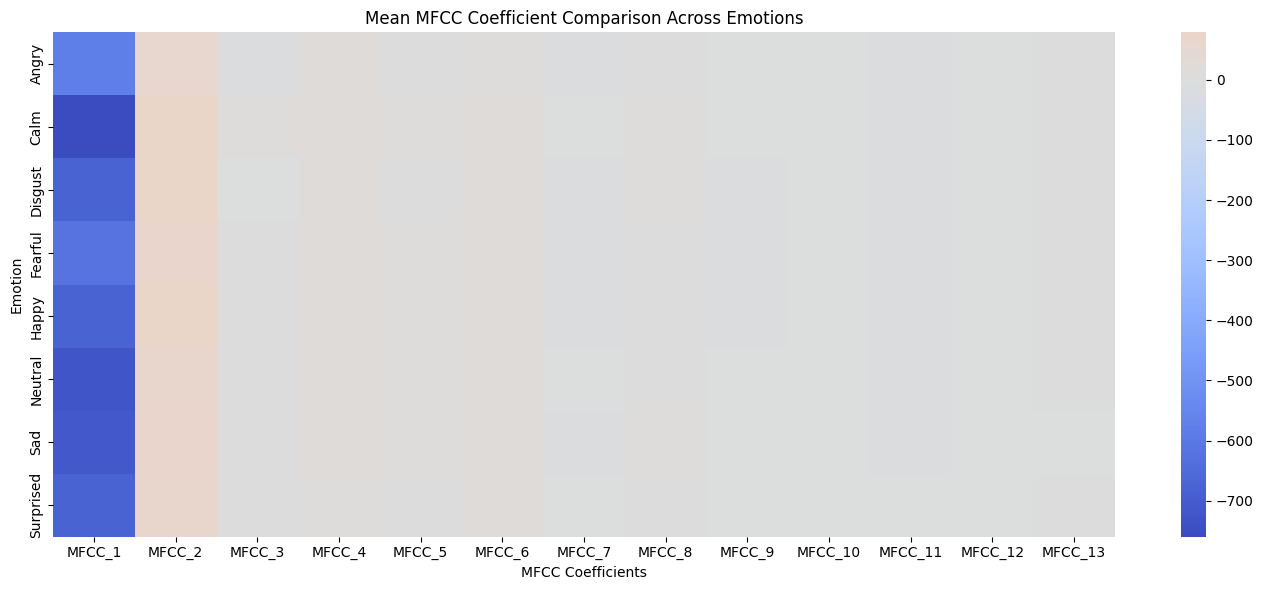

In [20]:
mfcc_plot_data = mfcc_statistics_df.set_index("emotion")

plt.figure(figsize=(14, 6))

sns.heatmap(
    mfcc_plot_data,
    cmap="coolwarm",
    center=0,
    annot=False
)

plt.title("Mean MFCC Coefficient Comparison Across Emotions")
plt.xlabel("MFCC Coefficients")
plt.ylabel("Emotion")

plt.tight_layout()
plt.show()

# Pitch and F0 Analysis

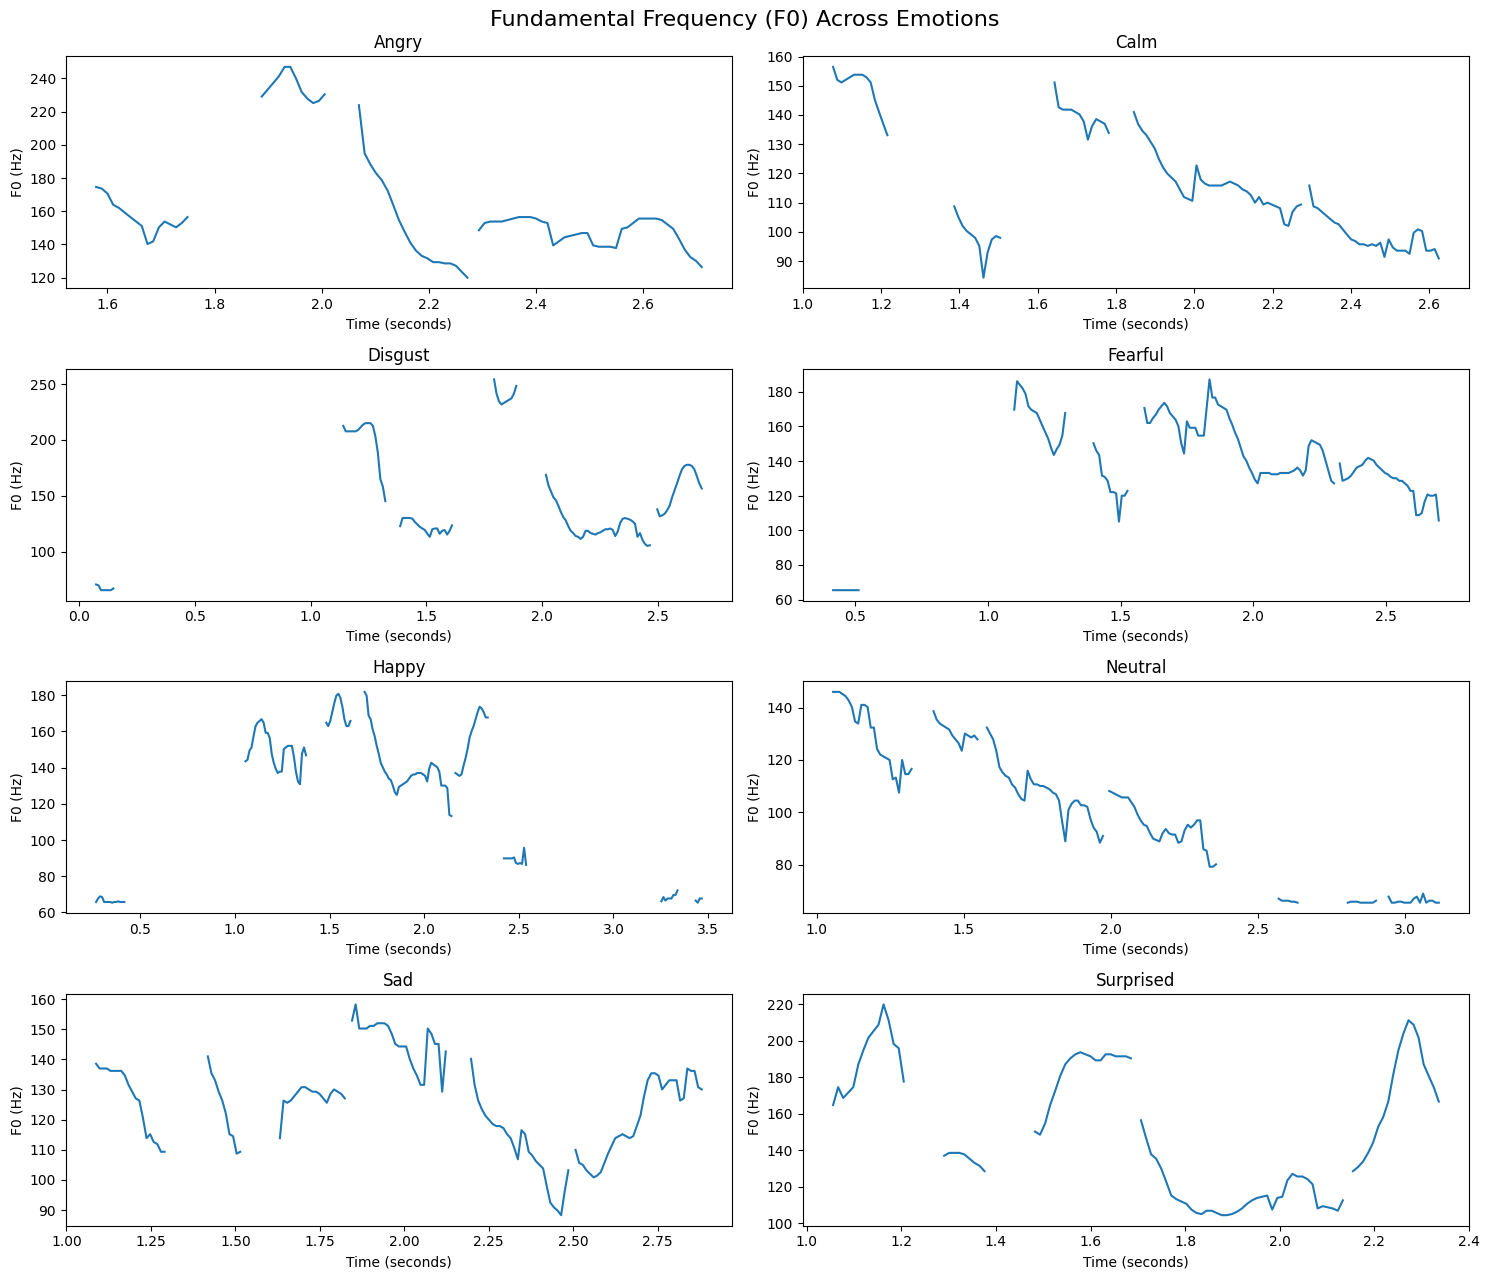

In [21]:
pitch_statistics = []

fig, axes = plt.subplots(
    nrows=4,
    ncols=2,
    figsize=(15, 13)
)

axes = axes.flatten()

for index, row in emotion_samples.iterrows():

    audio, sr = librosa.load(
        row["file_path"],
        sr=None
    )

    f0, voiced_flag, voiced_prob = librosa.pyin(
        audio,
        fmin=librosa.note_to_hz("C2"),
        fmax=librosa.note_to_hz("C7"),
        sr=sr,
        frame_length=2048,
        hop_length=512
    )

    times = librosa.times_like(
        f0,
        sr=sr,
        hop_length=512
    )

    axes[index].plot(times, f0)

    axes[index].set_title(row["emotion_label"])
    axes[index].set_xlabel("Time (seconds)")
    axes[index].set_ylabel("F0 (Hz)")

    # Remove unvoiced frames
    valid_f0 = f0[voiced_flag]

    pitch_statistics.append({
        "emotion": row["emotion_label"],
        "mean_f0": np.mean(valid_f0) if len(valid_f0) else np.nan,
        "median_f0": np.median(valid_f0) if len(valid_f0) else np.nan,
        "std_f0": np.std(valid_f0) if len(valid_f0) else np.nan,
        "min_f0": np.min(valid_f0) if len(valid_f0) else np.nan,
        "max_f0": np.max(valid_f0) if len(valid_f0) else np.nan,
        "voiced_frames": np.sum(voiced_flag),
        "total_frames": len(f0)
    })

plt.suptitle(
    "Fundamental Frequency (F0) Across Emotions",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [22]:
pitch_statistics_df = pd.DataFrame(pitch_statistics)

pitch_statistics_df

,emotion,mean_f0,median_f0,std_f0,min_f0,max_f0,voiced_frames,total_frames
0,Angry,162.049414,153.776693,32.712395,119.955851,246.941651,89,363
1,Calm,116.408019,111.922766,19.300892,84.333059,156.464662,113,332
2,Disgust,146.019709,129.684813,45.500393,65.406391,254.177593,120,363
3,Fearful,139.093398,137.396273,27.091106,65.406391,187.146775,146,345
4,Happy,128.046337,136.999458,36.593402,65.406391,181.819070,145,326
5,Neutral,101.164832,104.126904,24.620576,65.406391,145.986692,148,310
6,Sad,125.486273,127.825015,15.390267,88.321517,158.282694,140,360
7,Surprised,150.866223,138.591315,35.579084,104.427633,220.000000,103,320


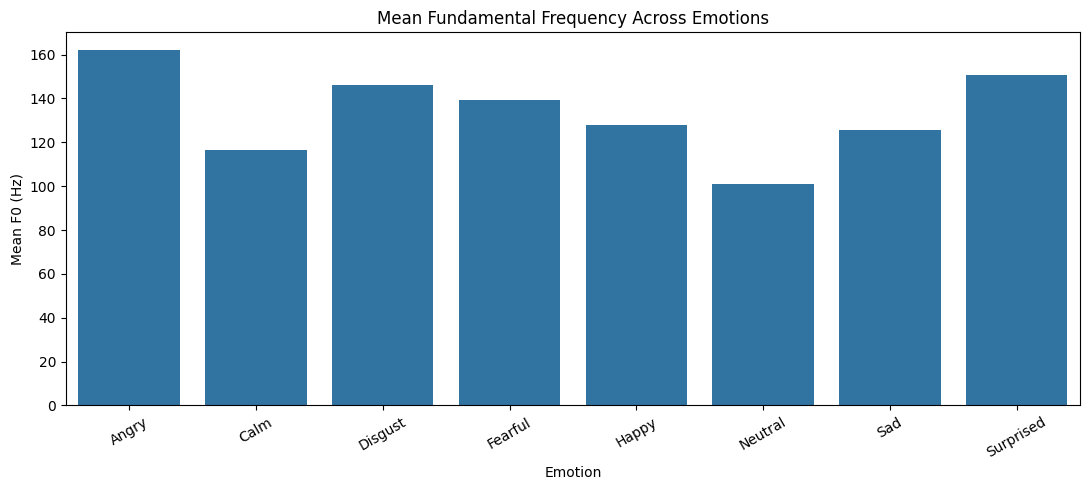

In [23]:
plt.figure(figsize=(11, 5))

sns.barplot(
    data=pitch_statistics_df,
    x="emotion",
    y="mean_f0"
)

plt.title("Mean Fundamental Frequency Across Emotions")
plt.xlabel("Emotion")
plt.ylabel("Mean F0 (Hz)")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

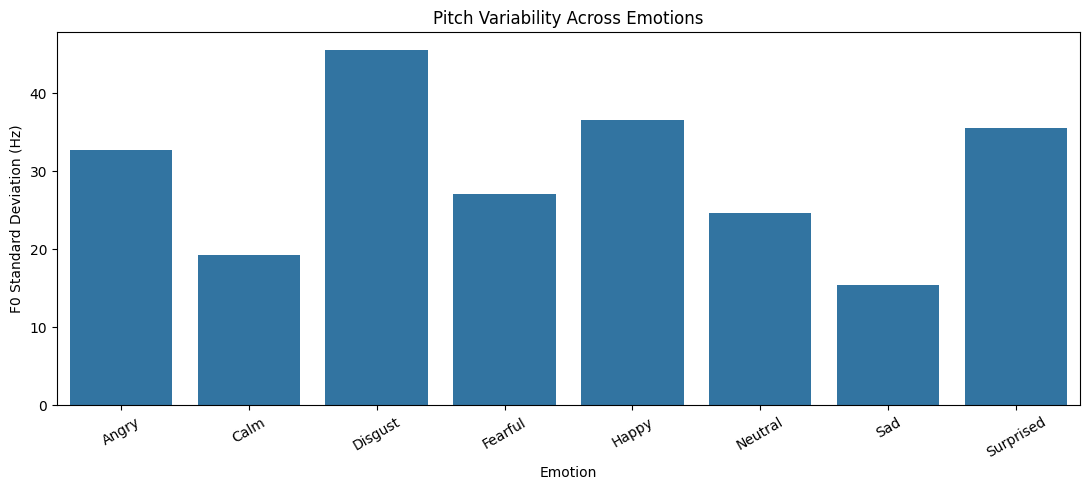

In [24]:
plt.figure(figsize=(11, 5))

sns.barplot(
    data=pitch_statistics_df,
    x="emotion",
    y="std_f0"
)

plt.title("Pitch Variability Across Emotions")
plt.xlabel("Emotion")
plt.ylabel("F0 Standard Deviation (Hz)")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

# RMS Energy and ZCR Analysis

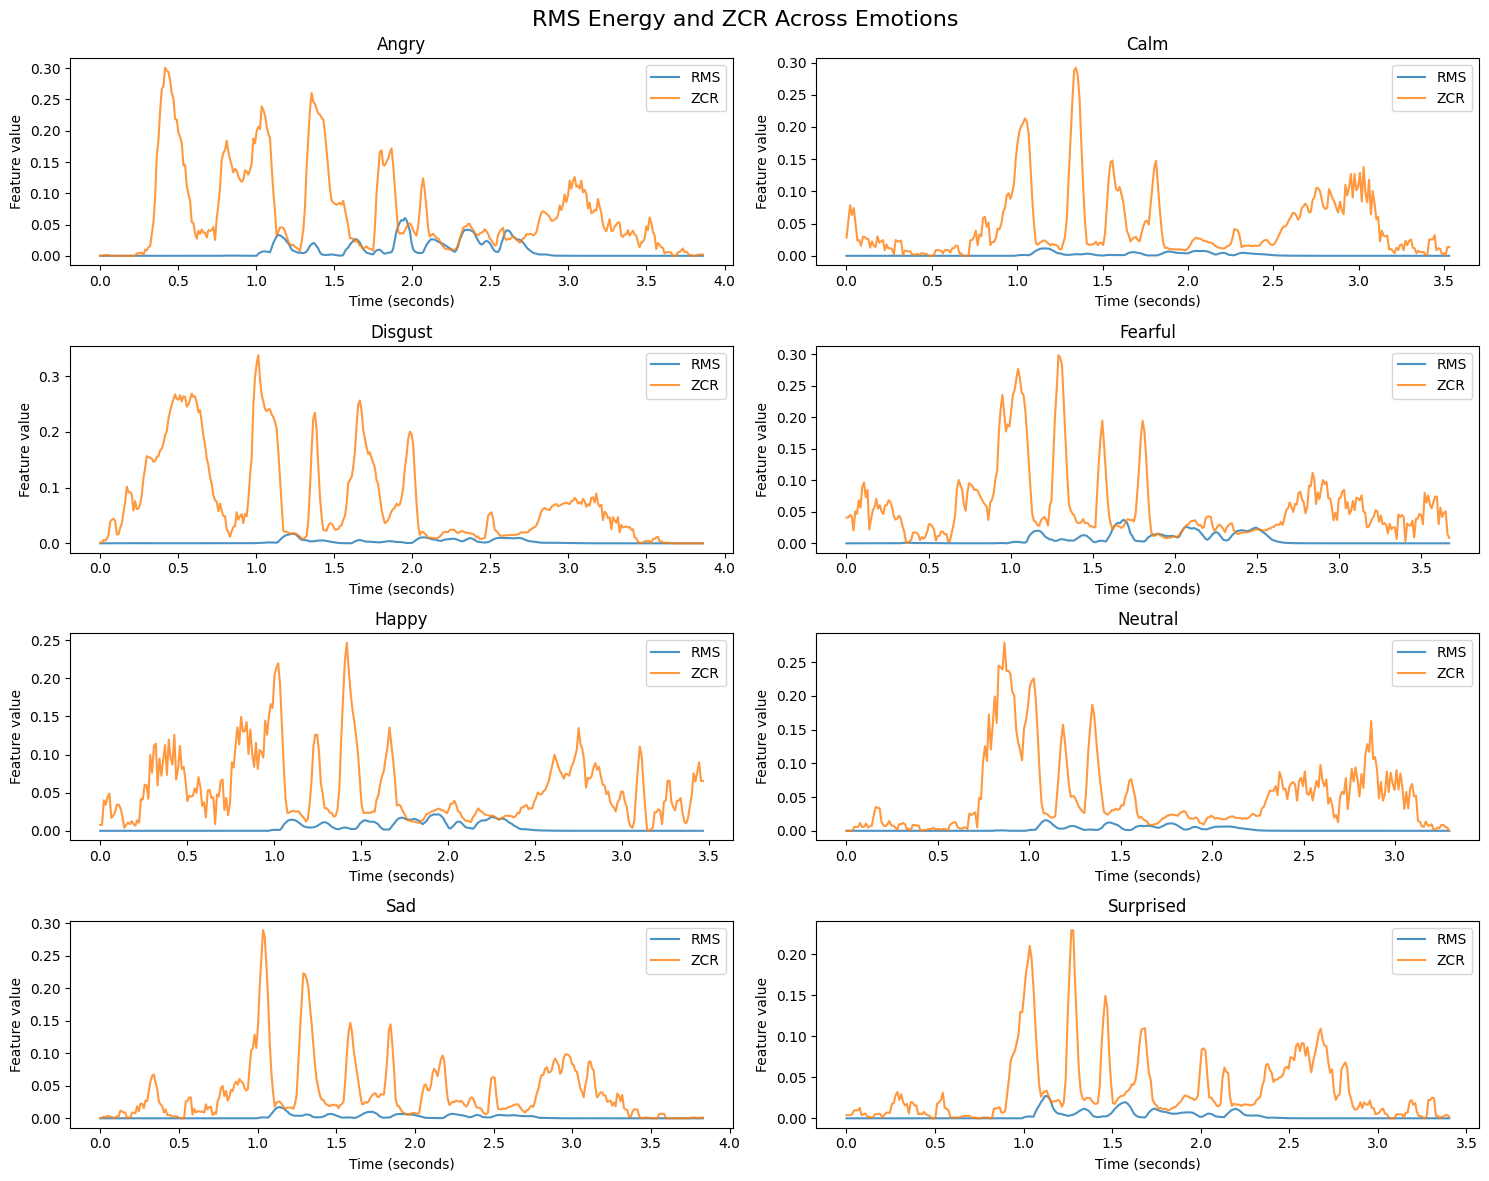

In [25]:
acoustic_statistics = []

fig, axes = plt.subplots(
    nrows=4,
    ncols=2,
    figsize=(15, 12)
)

axes = axes.flatten()

for index, row in emotion_samples.iterrows():

    audio, sr = librosa.load(
        row["file_path"],
        sr=None
    )

    # RMS Energy
    rms = librosa.feature.rms(
        y=audio,
        frame_length=2048,
        hop_length=512
    )[0]

    # Zero Crossing Rate
    zcr = librosa.feature.zero_crossing_rate(
        y=audio,
        frame_length=2048,
        hop_length=512
    )[0]

    times = librosa.times_like(
        rms,
        sr=sr,
        hop_length=512
    )

    axes[index].plot(
        times,
        rms,
        label="RMS",
        alpha=0.8
    )

    axes[index].plot(
        times,
        zcr,
        label="ZCR",
        alpha=0.8
    )

    axes[index].set_title(row["emotion_label"])
    axes[index].set_xlabel("Time (seconds)")
    axes[index].set_ylabel("Feature value")
    axes[index].legend()

    acoustic_statistics.append({
        "emotion": row["emotion_label"],
        "mean_rms": np.mean(rms),
        "std_rms": np.std(rms),
        "mean_zcr": np.mean(zcr),
        "std_zcr": np.std(zcr)
    })

plt.suptitle(
    "RMS Energy and ZCR Across Emotions",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [26]:
acoustic_statistics_df = pd.DataFrame(acoustic_statistics)

acoustic_statistics_df

,emotion,mean_rms,std_rms,mean_zcr,std_zcr
0,Angry,0.008106,0.012694,0.068893,0.069217
1,Calm,0.001579,0.002497,0.045929,0.051376
2,Disgust,0.002500,0.003643,0.075787,0.080164
3,Fearful,0.005674,0.008353,0.058843,0.056785
4,Happy,0.004056,0.005907,0.055702,0.045034
5,Neutral,0.002120,0.003391,0.050476,0.055781
6,Sad,0.002030,0.003138,0.039407,0.047020
7,Surprised,0.002915,0.005024,0.034964,0.041550


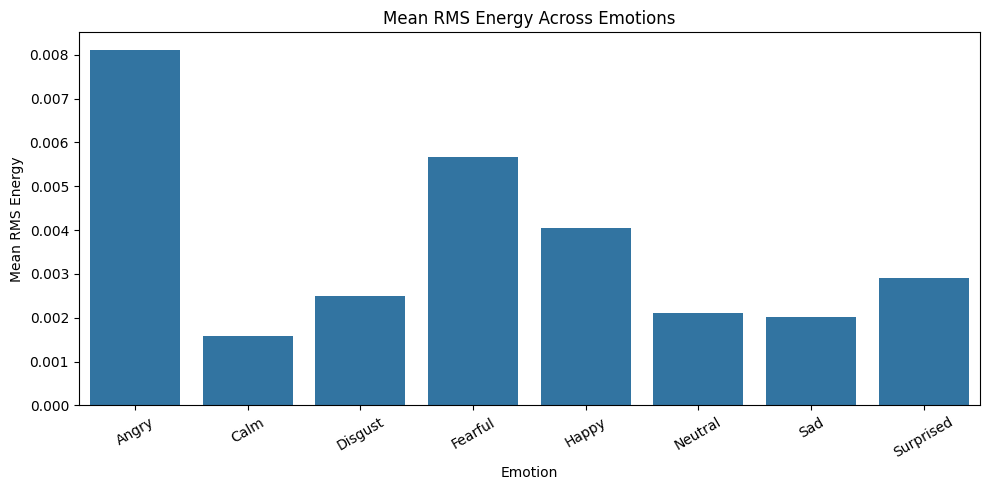

In [27]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=acoustic_statistics_df,
    x="emotion",
    y="mean_rms"
)

plt.title("Mean RMS Energy Across Emotions")
plt.xlabel("Emotion")
plt.ylabel("Mean RMS Energy")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

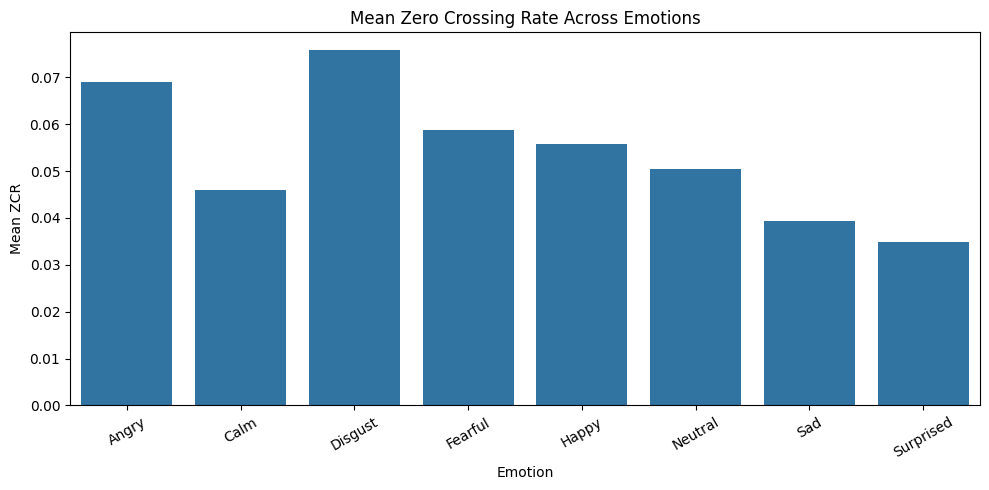

In [28]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=acoustic_statistics_df,
    x="emotion",
    y="mean_zcr"
)

plt.title("Mean Zero Crossing Rate Across Emotions")
plt.xlabel("Emotion")
plt.ylabel("Mean ZCR")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

# Spectral Feature Analysis

In [29]:
spectral_statistics = []

for _, row in emotion_samples.iterrows():

    audio, sr = librosa.load(row["file_path"], sr=None)

    centroid = librosa.feature.spectral_centroid(
        y=audio, sr=sr, n_fft=2048, hop_length=512
    )[0]

    bandwidth = librosa.feature.spectral_bandwidth(
        y=audio, sr=sr, n_fft=2048, hop_length=512
    )[0]

    rolloff = librosa.feature.spectral_rolloff(
        y=audio, sr=sr, n_fft=2048, hop_length=512,
        roll_percent=0.85
    )[0]

    contrast = librosa.feature.spectral_contrast(
        y=audio, sr=sr, n_fft=2048, hop_length=512
    )

    flatness = librosa.feature.spectral_flatness(
        y=audio, n_fft=2048, hop_length=512
    )[0]

    spectral_statistics.append({
        "emotion": row["emotion_label"],

        "mean_centroid": np.mean(centroid),
        "std_centroid": np.std(centroid),

        "mean_bandwidth": np.mean(bandwidth),
        "std_bandwidth": np.std(bandwidth),

        "mean_rolloff": np.mean(rolloff),
        "std_rolloff": np.std(rolloff),

        "mean_contrast": np.mean(contrast),
        "std_contrast": np.std(contrast),

        "mean_flatness": np.mean(flatness),
        "std_flatness": np.std(flatness)
    })

spectral_statistics_df = pd.DataFrame(spectral_statistics)

spectral_statistics_df

,emotion,mean_centroid,std_centroid,mean_bandwidth,std_bandwidth,mean_rolloff,std_rolloff,mean_contrast,std_contrast,mean_flatness,std_flatness
0,Angry,6134.619097,3987.077395,4971.857653,2039.886564,11312.629132,7246.822135,14.971935,6.912993,0.234956,0.292419
1,Calm,6997.311810,4373.360791,5518.637359,1916.039762,12649.543486,7902.073642,13.867634,6.683030,0.250484,0.284655
2,Disgust,5563.617307,3676.123430,5040.087309,1947.862796,10598.398760,7022.472539,15.082875,6.745260,0.183910,0.287968
3,Fearful,5823.188496,3526.059365,5566.043514,1909.936799,11950.611413,6866.373629,15.829228,6.611482,0.116354,0.167300
4,Happy,6697.877340,4251.305681,5448.887955,2046.578693,12494.560008,7762.127737,15.108421,6.597527,0.201490,0.217172
5,Neutral,7416.297748,4428.027505,5551.291828,1966.670942,13285.735887,7873.634242,13.716914,6.489106,0.267656,0.280900
6,Sad,6355.887480,4324.128938,5234.605321,2070.001900,11777.799479,7846.641791,13.821775,7.442943,0.288210,0.341297
7,Surprised,7174.304333,4454.405716,5480.721783,1973.601246,13011.767578,7871.292864,13.186916,7.268539,0.331193,0.341707


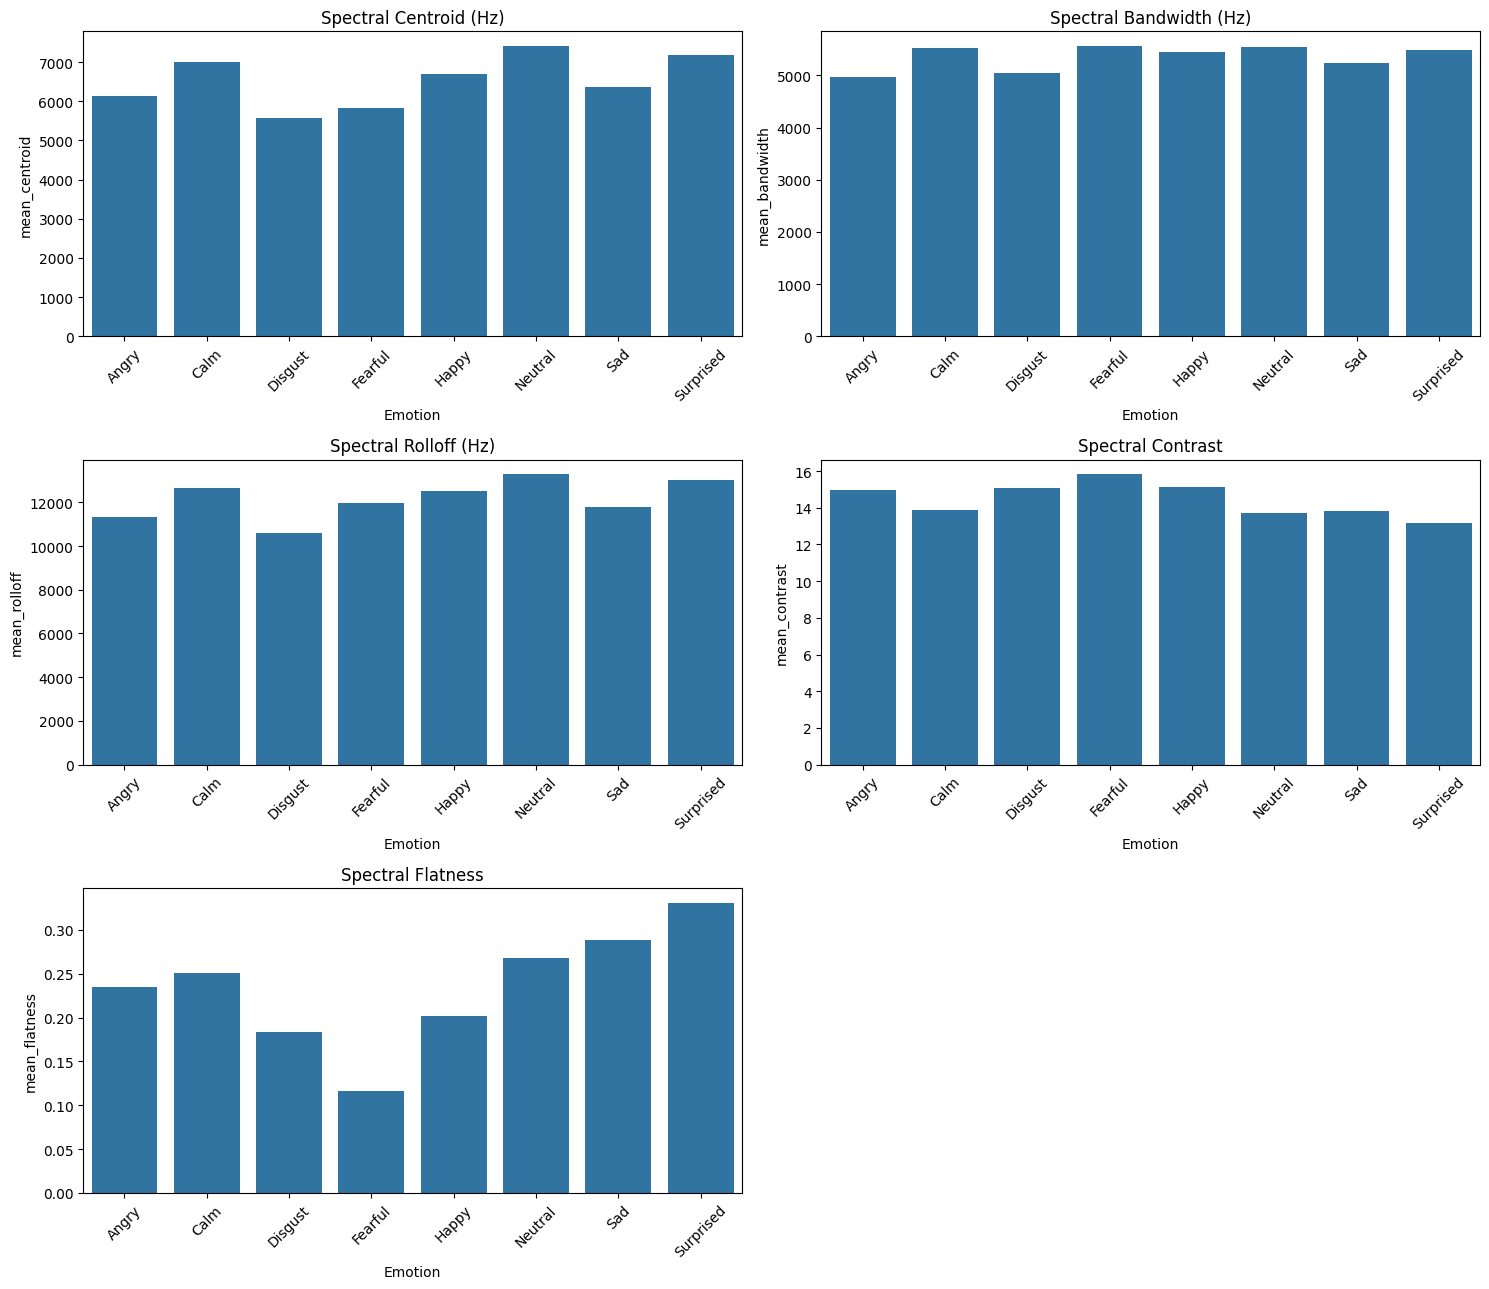

In [30]:
spectral_features = [
    ("mean_centroid", "Spectral Centroid (Hz)"),
    ("mean_bandwidth", "Spectral Bandwidth (Hz)"),
    ("mean_rolloff", "Spectral Rolloff (Hz)"),
    ("mean_contrast", "Spectral Contrast"),
    ("mean_flatness", "Spectral Flatness")
]

fig, axes = plt.subplots(3, 2, figsize=(15, 13))
axes = axes.flatten()

for index, (column, title) in enumerate(spectral_features):

    sns.barplot(
        data=spectral_statistics_df,
        x="emotion",
        y=column,
        ax=axes[index]
    )

    axes[index].set_title(title)
    axes[index].set_xlabel("Emotion")
    axes[index].tick_params(axis="x", rotation=45)

axes[-1].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Feature	What it tells us
# Centroid	Where the spectrum's centre of mass lies
# Bandwidth	How widely frequency energy is distributed
# Rolloff	How far up the frequency spectrum most energy extends
# Contrast	How prominent spectral peaks are relative to valleys
# Flatness	Whether the spectrum is more noise-like or tone-like